# Figure 5 — Brain-age prediction across cortical representations

Figure 5 compares cortical representation, spatial resolution, cortical-depth sampling density, and geometric information using matched outer-fold held-out predictions.

- **A:** complete overview of all models, ordered from lowest to highest MAE.
- **B:** spatial-resolution sequence from regional through full-resolution 21-depth MD profiles.
- **C:** ico4 depth-averaged MD followed by 6-, 11-, and 21-depth profiles.
- **D:** ico4 MD profile with length and curvature extensions.
- **Supplement:** regional 21-depth profile versus regional depth-averaged MD.

All metrics and subject-bootstrap confidence intervals use the same 196 participants. Paired exploratory statistics remain in the exported tables but are not densely annotated on the main panels.

## 1. Imports, colors, and plotting helpers (edit here)

All Figure 5 plotting styles and helper functions are defined directly below. The notebook does not import plotting code from another project file.

In [133]:
from __future__ import annotations

get_ipython().run_line_magic("matplotlib", "inline")

from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.stats import pearsonr
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

BOOTSTRAP_REPLICATES = 10_000
BOOTSTRAP_SEED = 20261028
QC_TOLERANCE = 1e-6
X_TICK_LABEL_SIZE = 7.5
POINT_MARKER = "o"  # All models use circles; color carries the visual distinction.
FIGURE_WIDTH_IN = 7.09
RASTER_DPI = 600

# Edit Figure 5 colors here. Overview color and grouped-panel colors are intentionally separate.
PALETTE = {
    "blue": "#4B74B2",
    "light_blue": "#90BEE0",
    "orange": "#FC8C5A",
    "red": "#DB3124",
    "pale_yellow": "#FFDF92",
    "gray": "#8A8A8A",
    "reference": "#333333",
}
SERIES_COLORS = tuple(PALETTE[k] for k in ("blue", "red", "orange", "light_blue", "gray", "pale_yellow"))
OVERVIEW_COLOR = PALETTE["blue"]
MODEL_COLORS = {
    "regional_mean_md": OVERVIEW_COLOR, "regional_profile": OVERVIEW_COLOR,
    "regional_thickness": OVERVIEW_COLOR, "regional_profile_thickness": OVERVIEW_COLOR,
    "ico3_md": OVERVIEW_COLOR, "ico4_md": OVERVIEW_COLOR,
    "ico4_md_depth6": OVERVIEW_COLOR, "ico4_md_depth11": OVERVIEW_COLOR,
    "ico5_md": OVERVIEW_COLOR, "fsaverage_full_md": OVERVIEW_COLOR,
    "ico4_column_mean_md": OVERVIEW_COLOR, "ico4_md_length": OVERVIEW_COLOR,
    "ico4_md_curvature": OVERVIEW_COLOR, "ico4_md_length_curvature": OVERVIEW_COLOR,
}
GROUP_COLORS = {
    "spatial": {
        "regional_profile": PALETTE["blue"], "ico3_md": PALETTE["light_blue"],
        "ico4_md": PALETTE["red"], "ico5_md": PALETTE["orange"],
        "fsaverage_full_md": PALETTE["orange"],
    },
    "depth": {
        "ico4_column_mean_md": PALETTE["blue"], "ico4_md_depth6": PALETTE["light_blue"],
        "ico4_md_depth11": PALETTE["orange"], "ico4_md": PALETTE["red"],
    },
    "geometry": {
        "ico4_md": PALETTE["red"], "ico4_md_length": PALETTE["orange"],
        "ico4_md_curvature": PALETTE["light_blue"],
        "ico4_md_length_curvature": PALETTE["blue"],
    },
    "supplement": {
        "regional_profile": PALETTE["red"],
        "regional_mean_md": PALETTE["blue"],
    },
}

def apply_semantic_style():
    mpl.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
        "text.color": "#333333", "axes.labelcolor": "#333333",
        "axes.titlecolor": "#333333", "xtick.color": "#333333", "ytick.color": "#333333",
        "axes.edgecolor": "#555555", "axes.facecolor": "white", "figure.facecolor": "white",
        "axes.prop_cycle": mpl.cycler(color=SERIES_COLORS),
        "axes.grid": False, "axes.linewidth": .8,
        "axes.spines.top": False, "axes.spines.right": False,
        "xtick.direction": "out", "ytick.direction": "out",
        "xtick.major.size": 3, "ytick.major.size": 3,
        "xtick.major.width": .8, "ytick.major.width": .8,
        "legend.frameon": False, "legend.facecolor": "white",
        "legend.edgecolor": "#D0D0D0", "legend.framealpha": .90,
        "legend.fancybox": False, "legend.borderpad": .35,
        "legend.labelspacing": .35, "legend.handlelength": 1.8,
        "legend.handletextpad": .5, "lines.markeredgewidth": 0,
    })

def set_publication_style():
    mpl.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
        "font.size": 8, "axes.labelsize": 8.5, "axes.titlesize": 8.5,
        "xtick.labelsize": X_TICK_LABEL_SIZE, "ytick.labelsize": 7.5, "legend.fontsize": 7.5,
        "axes.linewidth": .8, "lines.linewidth": 1.8, "lines.markersize": 3.0,
        "axes.prop_cycle": mpl.cycler(color=SERIES_COLORS),
        "figure.dpi": 120, "savefig.dpi": RASTER_DPI,
        "savefig.facecolor": "white", "savefig.edgecolor": "white",
        "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none",
    })
    apply_semantic_style()

def style_axes(ax):
    ax.set_facecolor("white")
    ax.grid(False, which="both", axis="both")
    ax.spines[["top", "right"]].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_linewidth(.8)
        ax.spines[side].set_color("#555555")
    ax.tick_params(width=.8, length=3, pad=2, direction="out", colors="#333333")

def finalize_figure(fig):
    # Final Figure 5 styling is local to this notebook so it can be edited here.
    import re
    import textwrap
    from matplotlib.collections import PathCollection

    for ax in fig.axes:
        if ax.name != "3d" and not hasattr(ax, "_colorbar"):
            style_axes(ax)
        else:
            ax.grid(False)
        ax.xaxis.label.set(fontsize=11.5, color="#333333")
        ax.yaxis.label.set(fontsize=11.5, color="#333333")
        if ax.get_gid() == "group_mae_panel":
            ax.tick_params(axis="x", labelsize=9.5)
            ax.tick_params(axis="y", labelsize=11)
        elif ax.get_gid() == "overview_mae_panel":
            ax.tick_params(axis="x", labelsize=11, width=1.0, length=4)
            ax.tick_params(axis="y", labelsize=11, width=0, length=0, pad=8)
        else:
            ax.tick_params(labelsize=11)
        for text in (ax.title, ax._left_title, ax._right_title):
            text.set_text(re.sub(r"^(?:[A-Da-d][.):]?|S\d+[A-Da-d])\s+", "", text.get_text()))
            text.set(fontsize=11 if ax.get_gid() == "overview_mae_panel" else 13, color="#333333")
            if ax.name != "3d" and "$" not in text.get_text():
                width = max(24, int(fig.get_figwidth() * ax.get_position().width * 72 / 4.5))
                text.set_text("\n".join(textwrap.fill(line, width=width, break_long_words=False)
                                          for line in text.get_text().split("\n")))
        for text in ax.texts:
            text.set(fontsize=min(text.get_fontsize(), 11), color="#333333")
        for line in ax.lines:
            if line.get_gid() not in {"metric_point", "metric_error"}:
                line.set_linewidth(min(line.get_linewidth(), 1.9 if line.get_gid() == "derived_result_line" else 1.8))
                line.set_markersize(min(line.get_markersize(), 3.2))
                line.set_markeredgewidth(min(line.get_markeredgewidth(), .5))
        for collection in ax.collections:
            if "FillBetween" in type(collection).__name__ and collection.get_gid() != "subject_violin":
                collection.set_alpha(.16 if collection.get_gid() == "derived_result_band" else .12)
                collection.set_linewidth(0)
            elif isinstance(collection, PathCollection):
                collection.set_edgecolor("none")
                collection.set_sizes([min(s, 18) for s in collection.get_sizes()])
        legend = ax.get_legend()
        if legend is not None:
            if legend.get_frame_on():
                frame = legend.get_frame()
                frame.set_facecolor("white")
                frame.set_edgecolor("#D0D0D0")
                frame.set_alpha(.90)
                frame.set_linewidth(.6)
            for text in legend.get_texts():
                text.set(fontsize=11, color="#333333")
            for handle in legend.legend_handles:
                if hasattr(handle, "set_markersize"):
                    handle.set_markersize(3.2)
                if hasattr(handle, "set_linewidth"):
                    handle.set_linewidth(1.6)
    for text in fig.texts:
        size = 13 if text is fig._suptitle else min(text.get_fontsize(), 11)
        text.set(fontsize=size, color="#333333")
        width = max(30, int(fig.get_figwidth() * 72 * .95 / (size * .5)))
        text.set_text("\n".join(textwrap.fill(line, width=width, break_long_words=False)
                                  for line in text.get_text().split("\n")))

set_publication_style()

## 2. File paths, model mapping, and scientific groups

In [134]:
def find_repo_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "analysis_results/figure5").is_dir():
            return candidate
    raise RuntimeError("Could not locate repository root containing analysis_results/figure5")


REPO_ROOT = find_repo_root()
RESULTS_ROOT = Path("/mnt/newStor/paros/paros_WORK/xintong/results/figure5_age_prediction/outputs")
MODEL_ROOT = RESULTS_ROOT / "models_lsqr"
OUTPUT_DIR = REPO_ROOT / "analysis_results/figure5/outputs/figures"
STATISTICS_DIR = REPO_ROOT / "analysis_results/figure5/outputs/statistics"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BASE_SUMMARY = RESULTS_ROOT / "summary_lsqr/model_summary.csv"
PROFILE_THICKNESS_SUMMARY = RESULTS_ROOT / "regional_profile_thickness_analysis/model_summary.csv"
GEOMETRY_SUMMARY = RESULTS_ROOT / "ico4_geometry_analysis/ico4_geometry_model_summary.csv"
DEPTH_SUMMARY = RESULTS_ROOT / "depth_sampling_analysis/model_summary.csv"
SUBJECT_ORDER = RESULTS_ROOT / "features/subject_order.csv"
PAIRED_MAE_STATS = STATISTICS_DIR / "Figure5_paired_MAE_comparisons.csv"

MODEL_CONFIG = {
    "regional_mean_md": {"label": "Regional depth-averaged MD", "summary": BASE_SUMMARY, "color": MODEL_COLORS["regional_mean_md"]},
    "regional_profile": {"label": "Regional MD profile", "summary": BASE_SUMMARY, "color": MODEL_COLORS["regional_profile"]},
    "regional_thickness": {"label": "Regional thickness", "summary": BASE_SUMMARY, "color": MODEL_COLORS["regional_thickness"]},
    "regional_profile_thickness": {"label": "Regional MD profile + thickness", "summary": PROFILE_THICKNESS_SUMMARY, "color": MODEL_COLORS["regional_profile_thickness"]},
    "ico3_md": {"label": "ico3 MD profile", "summary": BASE_SUMMARY, "color": MODEL_COLORS["ico3_md"]},
    "ico4_md": {"label": "ico4 MD profile", "summary": BASE_SUMMARY, "color": MODEL_COLORS["ico4_md"]},
    "ico4_md_depth6": {"label": "ico4 MD profile (6 depths)", "summary": DEPTH_SUMMARY, "color": MODEL_COLORS["ico4_md_depth6"]},
    "ico4_md_depth11": {"label": "ico4 MD profile (11 depths)", "summary": DEPTH_SUMMARY, "color": MODEL_COLORS["ico4_md_depth11"]},
    "ico5_md": {"label": "ico5 MD profile", "summary": BASE_SUMMARY, "color": MODEL_COLORS["ico5_md"]},
    "fsaverage_full_md": {"label": "Full-resolution MD profile", "summary": BASE_SUMMARY, "color": MODEL_COLORS["fsaverage_full_md"]},
    "ico4_column_mean_md": {"label": "ico4 depth-averaged MD", "summary": DEPTH_SUMMARY, "color": MODEL_COLORS["ico4_column_mean_md"]},
    "ico4_md_length": {"label": "ico4 MD profile + length", "summary": GEOMETRY_SUMMARY, "color": MODEL_COLORS["ico4_md_length"]},
    "ico4_md_curvature": {"label": "ico4 MD profile + curvature", "summary": GEOMETRY_SUMMARY, "color": MODEL_COLORS["ico4_md_curvature"]},
    "ico4_md_length_curvature": {"label": "ico4 MD profile + length + curvature", "summary": GEOMETRY_SUMMARY, "color": MODEL_COLORS["ico4_md_length_curvature"]},
}

SPATIAL_KEYS = ["regional_profile", "ico3_md", "ico4_md", "ico5_md", "fsaverage_full_md"]
DEPTH_KEYS = ["ico4_column_mean_md", "ico4_md_depth6", "ico4_md_depth11", "ico4_md"]
GEOMETRY_KEYS = ["ico4_md", "ico4_md_length", "ico4_md_curvature", "ico4_md_length_curvature"]
SUPPLEMENT_KEYS = ["regional_profile", "regional_mean_md"]
PLOT_GROUPS = [("Spatial resolution", SPATIAL_KEYS), ("Depth sampling density", DEPTH_KEYS), ("Geometric information", GEOMETRY_KEYS)]
EXPECTED_MAE_ORDER = list(MODEL_CONFIG)  # Replaced by the validated ascending-MAE order after QC.

required_paths = [BASE_SUMMARY, PROFILE_THICKNESS_SUMMARY, GEOMETRY_SUMMARY, DEPTH_SUMMARY, SUBJECT_ORDER, PAIRED_MAE_STATS]
required_paths += [MODEL_ROOT / key / f"{key}_oof_predictions.csv" for key in MODEL_CONFIG]
missing = [str(p) for p in required_paths if not p.is_file()]
if missing:
    raise FileNotFoundError("Required Figure 5 inputs are missing:\n" + "\n".join(missing))

print(f"Repository root: {REPO_ROOT}")
print(f"Formal result root: {RESULTS_ROOT}")
print(f"Figure output directory: {OUTPUT_DIR}")

Repository root: /mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis
Formal result root: /mnt/newStor/paros/paros_WORK/xintong/results/figure5_age_prediction/outputs
Figure output directory: /mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis/analysis_results/figure5/outputs/figures


## 2A. Statistics for selected data and review pools

This section reports the six requested all-diagnosis pools and deliberately omits the current final 196-subject CN group: all metadata (N=448), complete Option 3 DWI (N=325), QC-passed analyzable DWI reference (N=320), no-observed-label-conflict candidates after coverage QC (N=259), the different-label review subset (N=54), and their All-QIAL all-label union (N=313). Normal, MCI, AD, Other/Impaired, and Unknown labels all remain in scope. The review groups are descriptive candidates only; models were not rerun.

For the 448-person metadata pool, age, diagnosis, and QIAL confidence are available for 369 subjects, while visit audit and profile coverage are available for the 325-person complete-DWI pool. In the QC-passed 320-person reference, 266 have no observed label conflict and 54 require different-label review; seven of the 266 fail 95% coverage, yielding 259 + 54 = 313. Missing values are shown explicitly and all percentages use the total N of each displayed pool.

`SUBJECT_SEX` codes are reported as stored because their codebook has not been verified. The generated selected-pool tables are stored under `analysis_results/figure5/cohort_selection/outputs/rule_statistics/selected_pool_*.csv`.

In [135]:
RULE_STATISTICS_DIR = REPO_ROOT / 'analysis_results/figure5/cohort_selection/outputs/rule_statistics'
SELECTED_DEFINITIONS = RULE_STATISTICS_DIR / 'selected_pool_definitions.csv'
SELECTED_SUMMARY = RULE_STATISTICS_DIR / 'selected_pool_summary.csv'
SELECTED_GROUP_COUNTS = RULE_STATISTICS_DIR / 'selected_pool_group_counts.csv'
SELECTED_AGE_BANDS = RULE_STATISTICS_DIR / 'selected_pool_age_band_counts.csv'

missing_pool_files = [str(path) for path in [SELECTED_DEFINITIONS, SELECTED_SUMMARY, SELECTED_GROUP_COUNTS, SELECTED_AGE_BANDS] if not path.is_file()]
if missing_pool_files:
    raise FileNotFoundError('Missing selected-pool statistics; run build_selected_pool_statistics.py:\n' + '\n'.join(missing_pool_files))

selected_pool_definitions = pd.read_csv(SELECTED_DEFINITIONS)
selected_pool_summary = pd.read_csv(SELECTED_SUMMARY)
selected_pool_group_counts = pd.read_csv(SELECTED_GROUP_COUNTS)
selected_pool_age_bands = pd.read_csv(SELECTED_AGE_BANDS)

display(Markdown('### Selected pool definitions'))
display(selected_pool_definitions[['pool_label', 'n_subjects', 'definition']])

display(Markdown('### Demographic and match summary'))
summary_columns = [
    'pool_label', 'n_subjects', 'age_n', 'age_missing_n', 'age_mean', 'age_sd', 'age_median', 'age_q25', 'age_q75',
    'sex_code_1_n', 'sex_code_2_n', 'sex_code_9_n',
    'qial_high_n', 'qial_medium_n', 'qial_low_n', 'qial_ambiguous_n', 'qial_missing_n',
    'visit_audit_n', 'visit_audit_missing_n', 'coverage_n', 'coverage_missing_n', 'coverage_mean', 'coverage_min',
]
display(selected_pool_summary[summary_columns].round(2))

display(Markdown('### Age bands (years)'))
display(selected_pool_age_bands.pivot(index='pool_label', columns='age_band', values='n').reset_index())

for variable in ['QIAL match confidence', 'Matched-visit diagnosis', 'SUBJECT_SEX code', 'Number of distinct visit dates', 'Longitudinal diagnosis audit', 'Profile coverage status']:
    display(Markdown(f'### {variable}'))
    display(selected_pool_group_counts.loc[selected_pool_group_counts['variable'].eq(variable)].reset_index(drop=True))

### Selected pool definitions

,pool_label,n_subjects,definition
0,All metadata subjects,448,"Complete metadata universe; imaging, QIAL conf..."
1,Complete Option 3 DWI pool,325,Complete Option 3 DWI profiles before manual r...
2,QC-passed analyzable DWI reference,320,All currently analyzable complete-DWI subjects...
3,No-observed-label-conflict candidate,259,All diagnoses and QIAL levels are allowed; ret...
4,Different-label review subset,54,All diagnoses and QIAL levels are allowed; con...
5,All-QIAL all-label maximum candidate,313,Largest currently computable registration-QC- ...


### Demographic and match summary

,pool_label,n_subjects,age_n,age_missing_n,age_mean,age_sd,age_median,age_q25,age_q75,sex_code_1_n,...,qial_medium_n,qial_low_n,qial_ambiguous_n,qial_missing_n,visit_audit_n,visit_audit_missing_n,coverage_n,coverage_missing_n,coverage_mean,coverage_min
0,All metadata subjects,448,369,79,57.90,11.67,58.0,50.0,67.00,172,...,163,56,28,79,325,123,325,123,0.98,0.02
1,Complete Option 3 DWI pool,325,325,0,57.92,11.88,58.0,50.0,68.00,118,...,145,47,28,0,325,0,325,0,0.98,0.02
2,QC-passed analyzable DWI reference,320,320,0,57.83,11.79,58.0,50.0,67.00,117,...,144,45,26,0,320,0,320,0,0.99,0.86
3,No-observed-label-conflict candidate,259,259,0,57.00,11.75,56.0,49.0,66.50,92,...,122,32,22,0,259,0,259,0,0.99,0.96
4,Different-label review subset,54,54,0,62.02,11.44,64.5,51.0,71.75,22,...,21,12,4,0,54,0,54,0,0.99,0.96
5,All-QIAL all-label maximum candidate,313,313,0,57.86,11.83,58.0,50.0,67.00,114,...,143,44,26,0,313,0,313,0,0.99,0.96


### Age bands (years)

age_band,pool_label,20-29,30-39,40-49,50-59,60-69,70-79,80-89,missing
0,All metadata subjects,2,23,61,126,81,75,1,79
1,All-QIAL all-label maximum candidate,2,19,55,102,70,64,1,0
2,Complete Option 3 DWI pool,2,21,56,104,74,67,1,0
3,Different-label review subset,0,2,8,9,17,17,1,0
4,No-observed-label-conflict candidate,2,17,47,93,53,47,0,0
5,QC-passed analyzable DWI reference,2,20,56,104,73,64,1,0


... (8 outputs left out)

### Longitudinal diagnosis audit

,pool_id,pool_label,variable,level,n,pct
0,all_metadata_448,All metadata subjects,Longitudinal diagnosis audit,missing visit audit,123,27.455357
1,all_metadata_448,All metadata subjects,Longitudinal diagnosis audit,long-gap diagnosis discordance,50,11.160714
2,all_metadata_448,All metadata subjects,Longitudinal diagnosis audit,no observed diagnosis discordance,269,60.044643
3,all_metadata_448,All metadata subjects,Longitudinal diagnosis audit,other distinct-date diagnosis discordance,2,0.446429
4,all_metadata_448,All metadata subjects,Longitudinal diagnosis audit,same-date diagnosis conflict,4,0.892857
5,complete_dwi_325,Complete Option 3 DWI pool,Longitudinal diagnosis audit,long-gap diagnosis discordance,50,15.384615
6,complete_dwi_325,Complete Option 3 DWI pool,Longitudinal diagnosis audit,no observed diagnosis discordance,269,82.769231
7,complete_dwi_325,Complete Option 3 DWI pool,Longitudinal diagnosis audit,other distinct-date diagnosis discordance,2,0.615385
8,complete_dwi_325,Complete Option 3 DWI pool,Longitudinal diagnosis audit,same-date diagnosis conflict,4,1.230769
9,qc_pass_dwi_320,QC-passed analyzable DWI reference,Longitudinal diagnosis audit,long-gap diagnosis discordance,48,15.000000


### Profile coverage status

,pool_id,pool_label,variable,level,n,pct
0,all_metadata_448,All metadata subjects,Profile coverage status,missing profile coverage,123,27.455357
1,all_metadata_448,All metadata subjects,Profile coverage status,>=95%,317,70.758929
2,all_metadata_448,All metadata subjects,Profile coverage status,<95%,8,1.785714
3,complete_dwi_325,Complete Option 3 DWI pool,Profile coverage status,>=95%,317,97.538462
4,complete_dwi_325,Complete Option 3 DWI pool,Profile coverage status,<95%,8,2.461538
5,qc_pass_dwi_320,QC-passed analyzable DWI reference,Profile coverage status,>=95%,313,97.812500
6,qc_pass_dwi_320,QC-passed analyzable DWI reference,Profile coverage status,<95%,7,2.187500
7,no_label_conflict_259,No-observed-label-conflict candidate,Profile coverage status,>=95%,259,100.000000
8,different_label_review_54,Different-label review subset,Profile coverage status,>=95%,54,100.000000
9,all_qial_all_labels_313,All-QIAL all-label maximum candidate,Profile coverage status,>=95%,313,100.000000


## 3. Read model summaries and OOF predictions

In [136]:
summary_tables = {p: pd.read_csv(p) for p in {c["summary"] for c in MODEL_CONFIG.values()}}
subject_order = pd.read_csv(SUBJECT_ORDER)
required_subject_columns = {"row_index", "subject_id", "age_at_scan"}
if not required_subject_columns.issubset(subject_order.columns):
    raise RuntimeError(f"subject_order.csv lacks columns: {required_subject_columns - set(subject_order.columns)}")
if subject_order["row_index"].duplicated().any() or subject_order["subject_id"].duplicated().any():
    raise RuntimeError("subject_order.csv contains duplicate row_index or subject_id values")

summary_rows, predictions = [], {}
for key, config in MODEL_CONFIG.items():
    matched = summary_tables[config["summary"]].loc[lambda x: x["representation"].eq(key)]
    if len(matched) != 1:
        raise RuntimeError(f"Expected exactly one summary row for {key}; found {len(matched)}")
    row = matched.iloc[0]
    summary_rows.append({
        "representation": key, "model": config["label"], "summary_n": int(row["n"]),
        "summary_mae": float(row["mae"]), "summary_pearson_r": float(row["pearson_r"]),
        "summary_source": str(config["summary"]),
    })
    p = MODEL_ROOT / key / f"{key}_oof_predictions.csv"
    frame = pd.read_csv(p)
    required = {"row_index", "true_age", "predicted_age"}
    if not required.issubset(frame.columns):
        raise RuntimeError(f"{p} lacks columns: {required - set(frame.columns)}")
    frame = (frame[["row_index", "true_age", "predicted_age"]]
             .merge(subject_order[["row_index", "subject_id", "age_at_scan"]],
                    on="row_index", how="left", validate="one_to_one")
             .sort_values("row_index").reset_index(drop=True))
    predictions[key] = frame

summary_df = pd.DataFrame(summary_rows).set_index("representation")
summary_df

,model,summary_n,summary_mae,summary_pearson_r,summary_source
representation,,,,,
regional_mean_md,Regional depth-averaged MD,196,6.080992,0.661741,/mnt/newStor/paros/paros_WORK/xintong/results/...
regional_profile,Regional MD profile,196,5.638254,0.717386,/mnt/newStor/paros/paros_WORK/xintong/results/...
regional_thickness,Regional thickness,196,5.989418,0.698314,/mnt/newStor/paros/paros_WORK/xintong/results/...
regional_profile_thickness,Regional MD profile + thickness,196,5.579632,0.732607,/mnt/newStor/paros/paros_WORK/xintong/results/...
ico3_md,ico3 MD profile,196,5.686713,0.716631,/mnt/newStor/paros/paros_WORK/xintong/results/...
ico4_md,ico4 MD profile,196,5.290518,0.761166,/mnt/newStor/paros/paros_WORK/xintong/results/...
ico4_md_depth6,ico4 MD profile (6 depths),196,5.300022,0.761787,/mnt/newStor/paros/paros_WORK/xintong/results/...
ico4_md_depth11,ico4 MD profile (11 depths),196,5.289505,0.761464,/mnt/newStor/paros/paros_WORK/xintong/results/...
ico5_md,ico5 MD profile,196,5.363515,0.757462,/mnt/newStor/paros/paros_WORK/xintong/results/...


## 4. Subject and result QC

In [137]:
if len(MODEL_CONFIG) != 14:
    raise RuntimeError("Model mapping does not contain exactly the 14 requested representations")
grouped_keys = {key for _, keys in PLOT_GROUPS for key in keys} | set(SUPPLEMENT_KEYS)
if not grouped_keys.issubset(MODEL_CONFIG):
    raise RuntimeError("A requested scientific plot group contains an unknown representation")

reference = predictions["regional_mean_md"]
if len(reference) != 196:
    raise RuntimeError(f"Expected 196 subjects; found {len(reference)}")

qc_rows = []
for key, frame in predictions.items():
    if len(frame) != 196:
        raise RuntimeError(f"{key}: expected 196 OOF predictions; found {len(frame)}")
    if frame["row_index"].duplicated().any() or frame["subject_id"].duplicated().any():
        raise RuntimeError(f"{key}: duplicate subject or row_index")
    if frame[["true_age", "predicted_age", "subject_id"]].isna().any().any():
        raise RuntimeError(f"{key}: missing subject ID, true age, or prediction")
    if not np.array_equal(frame["subject_id"].to_numpy(), reference["subject_id"].to_numpy()):
        raise RuntimeError(f"{key}: subject IDs/order differ after row-index merge")
    if not np.allclose(frame["true_age"], reference["true_age"], atol=0, rtol=0):
        raise RuntimeError(f"{key}: true ages differ from reference")
    if not np.allclose(frame["true_age"], frame["age_at_scan"], atol=0, rtol=0):
        raise RuntimeError(f"{key}: true ages disagree with subject_order.csv")

    y_true = frame["true_age"].to_numpy(float)
    y_pred = frame["predicted_age"].to_numpy(float)
    values = {
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "pearson_r": float(pearsonr(y_true, y_pred).statistic),
        "r2": float(r2_score(y_true, y_pred)),
    }
    mae_diff = abs(values["mae"] - summary_df.loc[key, "summary_mae"])
    r_diff = abs(values["pearson_r"] - summary_df.loc[key, "summary_pearson_r"])
    if summary_df.loc[key, "summary_n"] != 196 or mae_diff >= QC_TOLERANCE or r_diff >= QC_TOLERANCE:
        raise RuntimeError(f"{key}: recalculated metrics disagree with saved summary (MAE diff={mae_diff:.3g}, r diff={r_diff:.3g})")
    qc_rows.append({"representation": key, "model": MODEL_CONFIG[key]["label"], "n": 196, **values,
                    "mae_abs_difference": mae_diff, "pearson_r_abs_difference": r_diff})

qc_df = pd.DataFrame(qc_rows)
actual_order = qc_df.sort_values("mae")["representation"].tolist()
EXPECTED_MAE_ORDER = actual_order

print("QC PASSED: 14 models × 196 unique matched subjects; ages and saved metrics agree.")
display(qc_df.set_index("representation").loc[EXPECTED_MAE_ORDER].reset_index())

QC PASSED: 14 models × 196 unique matched subjects; ages and saved metrics agree.


,representation,model,n,mae,rmse,pearson_r,r2,mae_abs_difference,pearson_r_abs_difference
0,ico4_md_length,ico4 MD profile + length,196,5.233371,6.850516,0.769829,0.574227,0.0,0.000000e+00
1,ico4_md_length_curvature,ico4 MD profile + length + curvature,196,5.246867,6.850627,0.770821,0.574213,0.0,0.000000e+00
2,ico4_md_depth11,ico4 MD profile (11 depths),196,5.289505,6.930984,0.761464,0.564166,0.0,0.000000e+00
3,ico4_md,ico4 MD profile,196,5.290518,6.938888,0.761166,0.563171,0.0,0.000000e+00
4,ico4_md_curvature,ico4 MD profile + curvature,196,5.298498,6.935460,0.762435,0.563603,0.0,1.110223e-16
5,ico4_md_depth6,ico4 MD profile (6 depths),196,5.300022,6.919853,0.761787,0.565565,0.0,0.000000e+00
6,ico5_md,ico5 MD profile,196,5.363515,6.992468,0.757462,0.556399,0.0,1.110223e-16
7,fsaverage_full_md,Full-resolution MD profile,196,5.373040,6.970606,0.759687,0.559169,0.0,0.000000e+00
8,ico4_column_mean_md,ico4 depth-averaged MD,196,5.440511,7.099988,0.741245,0.542652,0.0,1.110223e-16
9,regional_profile_thickness,Regional MD profile + thickness,196,5.579632,7.160148,0.732607,0.534869,0.0,0.000000e+00


## 5. Subject-level bootstrap CIs for MAE, RMSE, Pearson r, and R²

In [138]:
rng = np.random.default_rng(BOOTSTRAP_SEED)
n_subjects = len(reference)
bootstrap_indices = rng.integers(0, n_subjects, size=(BOOTSTRAP_REPLICATES, n_subjects))
true_age = reference["true_age"].to_numpy(float)
boot_true = true_age[bootstrap_indices]
boot_true_centered = boot_true - boot_true.mean(axis=1, keepdims=True)
boot_true_ss = np.sum(boot_true_centered ** 2, axis=1)
if np.any(boot_true_ss == 0):
    raise RuntimeError("A bootstrap sample has zero true-age variance")

point_table = qc_df.set_index("representation")
ci_rows = []
for key in MODEL_CONFIG:
    predicted = predictions[key]["predicted_age"].to_numpy(float)
    residual = predicted - true_age
    boot_residual = residual[bootstrap_indices]
    boot_mae = np.mean(np.abs(boot_residual), axis=1)
    boot_rmse = np.sqrt(np.mean(boot_residual ** 2, axis=1))
    boot_predicted = predicted[bootstrap_indices]
    boot_pred_centered = boot_predicted - boot_predicted.mean(axis=1, keepdims=True)
    denom = np.sqrt(boot_true_ss * np.sum(boot_pred_centered ** 2, axis=1))
    if np.any(denom == 0):
        raise RuntimeError(f"{key}: zero variance in bootstrap Pearson-r sample")
    boot_r = np.sum(boot_true_centered * boot_pred_centered, axis=1) / denom
    boot_r2 = 1.0 - np.sum(boot_residual ** 2, axis=1) / boot_true_ss
    for metric, boot_values in (("mae", boot_mae), ("rmse", boot_rmse), ("pearson_r", boot_r), ("r2", boot_r2)):
        lower, upper = np.percentile(boot_values, [2.5, 97.5])
        ci_rows.append({
            "representation": key, "model": MODEL_CONFIG[key]["label"], "metric": metric,
            "estimate": float(point_table.loc[key, metric]), "ci95_lower": float(lower),
            "ci95_upper": float(upper), "n_subjects": n_subjects,
            "bootstrap_replicates": BOOTSTRAP_REPLICATES, "bootstrap_seed": BOOTSTRAP_SEED,
            "bootstrap_unit": "subject", "interval_method": "percentile",
        })

metric_ci = pd.DataFrame(ci_rows)
metric_ci.to_csv(OUTPUT_DIR / "Figure5_all_metrics_bootstrap_ci.csv", index=False)
print(f"Computed {len(metric_ci)} metric intervals using one shared subject-index matrix.")
display(metric_ci.head())

Computed 56 metric intervals using one shared subject-index matrix.


,representation,model,metric,estimate,ci95_lower,ci95_upper,n_subjects,bootstrap_replicates,bootstrap_seed,bootstrap_unit,interval_method
0,regional_mean_md,Regional depth-averaged MD,mae,6.080992,5.410109,6.793417,196,10000,20261028,subject,percentile
1,regional_mean_md,Regional depth-averaged MD,rmse,7.902251,7.039709,8.786864,196,10000,20261028,subject,percentile
2,regional_mean_md,Regional depth-averaged MD,pearson_r,0.661741,0.586737,0.732348,196,10000,20261028,subject,percentile
3,regional_mean_md,Regional depth-averaged MD,r2,0.433457,0.310578,0.531032,196,10000,20261028,subject,percentile
4,regional_profile,Regional MD profile,mae,5.638254,5.009890,6.307636,196,10000,20261028,subject,percentile


## 6. Prepare plotting data and statistical annotations

In [139]:
plot_data = metric_ci.copy()
plot_data["overview_color"] = OVERVIEW_COLOR
for group_name, color_map in GROUP_COLORS.items():
    plot_data[f"{group_name}_color"] = plot_data["representation"].map(color_map)
plot_data["marker"] = POINT_MARKER
plot_data["mae_rank"] = plot_data["representation"].map({k: i + 1 for i, k in enumerate(EXPECTED_MAE_ORDER)})
plot_data.to_csv(OUTPUT_DIR / "Figure5_plot_data.csv", index=False)

paired_stats = pd.read_csv(PAIRED_MAE_STATS)
expected_family_sizes = {"spatial_resolution": 4, "ico4_ablation": 4}
if paired_stats.groupby("family").size().to_dict() != expected_family_sizes:
    raise RuntimeError("Exploratory FDR table does not contain the expected 4+4 comparison families")
if paired_stats["fdr_bh_q"].isna().any():
    raise RuntimeError("Every comparison in the two exploratory FDR families must have a q value")

def exactly_one(a, b):
    match = paired_stats.loc[
        paired_stats["representation_a"].eq(a) & paired_stats["representation_b"].eq(b)
    ]
    if len(match) != 1:
        raise RuntimeError(f"Expected one saved comparison for {a} vs {b}; found {len(match)}")
    return match.iloc[0]

rp_ico4 = exactly_one("regional_profile", "ico4_md")
ico4_ico5 = exactly_one("ico4_md", "ico5_md")
ico5_full = exactly_one("ico5_md", "fsaverage_full_md")
column_ico4 = exactly_one("ico4_column_mean_md", "ico4_md")
ico4_length = exactly_one("ico4_md", "ico4_md_length")

paired_stats.to_csv(OUTPUT_DIR / "Figure5_exploratory_FDR_statistics.csv", index=False)
selected_stats = paired_stats.loc[
    paired_stats["comparison"].isin([
        "Regional 21-depth profile − ico4", "ico4 − ico5", "ico5 − full fsaverage",
        "ico4 column mean MD − ico4", "ico4 − ico4 + length",
    ])
].copy()
selected_stats.to_csv(OUTPUT_DIR / "Figure5_selected_paired_MAE_statistics.csv", index=False)
display(paired_stats[["family", "comparison", "delta_mae_a_minus_b", "ci95_lower", "ci95_upper",
                      "bootstrap_two_sided_p", "fdr_bh_q"]])

,family,comparison,delta_mae_a_minus_b,ci95_lower,ci95_upper,bootstrap_two_sided_p,fdr_bh_q
0,spatial_resolution,Regional 21-depth profile − ico3,-0.048459,-0.394110,0.291609,0.775322,0.775322
1,spatial_resolution,Regional 21-depth profile − ico4,0.347735,0.057046,0.665469,0.021598,0.086391
2,spatial_resolution,ico4 − ico5,-0.072997,-0.175077,0.027488,0.158584,0.317168
3,spatial_resolution,ico5 − full fsaverage,-0.009525,-0.049617,0.029524,0.632137,0.775322
4,ico4_ablation,ico4 column mean MD − ico4,0.149993,-0.057946,0.364215,0.161984,0.237310
5,ico4_ablation,ico4 − ico4 + length,0.057147,-0.000321,0.115386,0.053595,0.214379
6,ico4_ablation,ico4 − ico4 + curvature,-0.007980,-0.034948,0.018133,0.539946,0.539946
7,ico4_ablation,ico4 − ico4 + length + curvature,0.043651,-0.018046,0.107524,0.177982,0.237310


## 7. Figure 5A: complete MAE overview

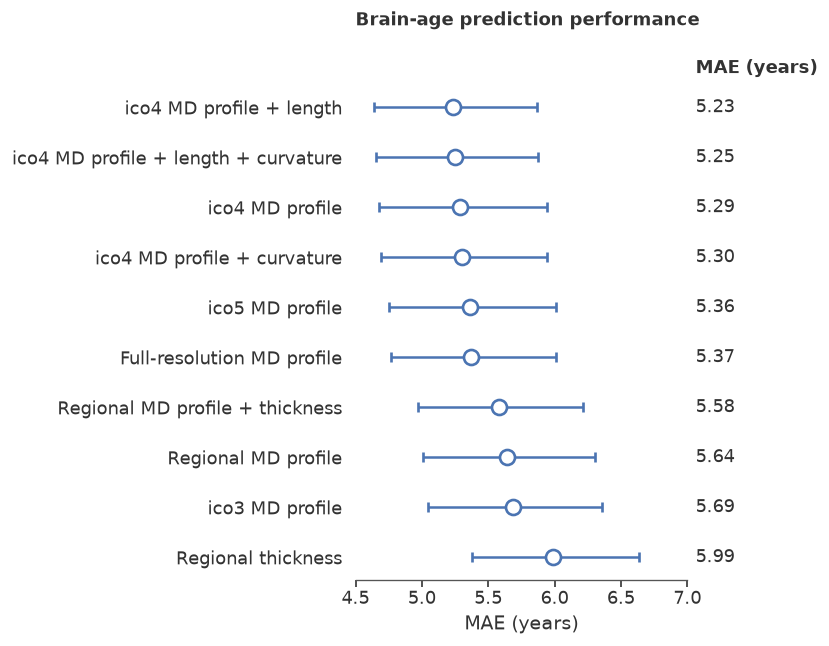

In [140]:
POINT_SIZE = 9.0
POINT_EDGE_WIDTH = 1.6
ERROR_LINE_WIDTH = 1.5
ERROR_CAP_SIZE = 3
ERROR_CAP_THICKNESS = 1.2

def save_figure(fig, stem):
    finalize_figure(fig)
    for suffix in ("png", "pdf", "svg"):
        kwargs = {"dpi": 600} if suffix == "png" else {}
        fig.savefig(OUTPUT_DIR / f"{stem}.{suffix}", bbox_inches="tight", facecolor="white", **kwargs)

def mae_axis_limits(keys, step=0.5):
    rows = metric_ci.loc[metric_ci["metric"].eq("mae")].set_index("representation").loc[keys]
    lower = np.floor(rows["ci95_lower"].min() / step) * step
    upper = np.ceil(rows["ci95_upper"].max() / step) * step
    return (float(lower), float(upper)), np.arange(lower, upper + step / 2, step)

OVERVIEW_EXCLUDED_KEYS = {"regional_mean_md", "ico4_column_mean_md", "ico4_md_depth6", "ico4_md_depth11"}
OVERVIEW_KEYS = [key for key in EXPECTED_MAE_ORDER if key not in OVERVIEW_EXCLUDED_KEYS]

def draw_mae_panel(ax, keys, title, xlim=None, xticks=None, label_overrides=None):
    rows = metric_ci.loc[metric_ci["metric"].eq("mae")].set_index("representation")
    y = np.arange(len(keys))
    ax.set_gid("overview_mae_panel")
    label_overrides = label_overrides or {}
    for ypos, key in zip(y, keys):
        row = rows.loc[key]
        color = MODEL_CONFIG[key]["color"]
        artists = ax.errorbar(
            row["estimate"], ypos,
            xerr=[[row["estimate"] - row["ci95_lower"]], [row["ci95_upper"] - row["estimate"]]],
            fmt=POINT_MARKER, markersize=POINT_SIZE, markerfacecolor="white",
            markeredgecolor=color, markeredgewidth=POINT_EDGE_WIDTH, color=color,
            ecolor=color, elinewidth=ERROR_LINE_WIDTH, capsize=ERROR_CAP_SIZE,
            capthick=ERROR_CAP_THICKNESS, zorder=3,
        )
        data_line, cap_lines, bar_collections = artists.lines
        data_line.set_gid("metric_point")
        for artist in (*cap_lines, *bar_collections):
            artist.set_gid("metric_error")
        ax.text(1.025, ypos, f"{row['estimate']:.2f}", transform=ax.get_yaxis_transform(),
                ha="left", va="center", fontsize=11, clip_on=False)
    labels = [label_overrides.get(key, MODEL_CONFIG[key]["label"]) for key in keys]
    ax.set_yticks(y, labels, fontsize=11)
    ax.invert_yaxis()
    ax.set_xlabel("MAE (years)", fontsize=11.5)
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold", y=1.08, pad=12)
    ax.text(1.025, 1.015, "MAE (years)", transform=ax.transAxes, ha="left", va="bottom",
            fontsize=11, fontweight="semibold", clip_on=False)
    if xlim is None or xticks is None:
        auto_xlim, auto_ticks = mae_axis_limits(keys)
        xlim = auto_xlim if xlim is None else xlim
        xticks = auto_ticks if xticks is None else xticks
    ax.set_xlim(*xlim)
    ax.set_xticks(xticks)
    ax.grid(False)
    ax.tick_params(axis="x", labelsize=11, width=1.0, length=4)
    ax.tick_params(axis="y", length=0, pad=8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    return rows.loc[keys]

def make_mae_figure(keys, title, stem, xlim=None, xticks=None, label_overrides=None):
    height = max(3.2, 0.42 * len(keys) + 1.45)
    fig, ax = plt.subplots(figsize=(7.09, height))
    draw_mae_panel(ax, keys, title, xlim=xlim, xticks=xticks, label_overrides=label_overrides)
    fig.subplots_adjust(left=0.43, right=0.82, bottom=0.15, top=0.88)
    save_figure(fig, stem)
    plt.show()
    return fig

fig_mae_overview = make_mae_figure(
    OVERVIEW_KEYS,
    "Brain-age prediction performance",
    "Figure5A_MAE",
)

## 8. Figure 5B–D: prespecified grouped MAE comparisons

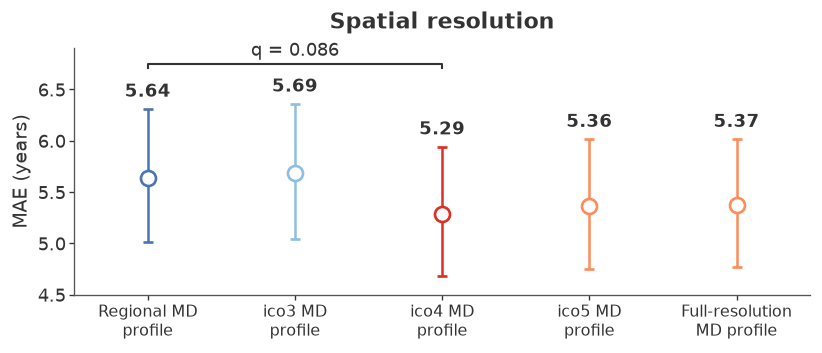

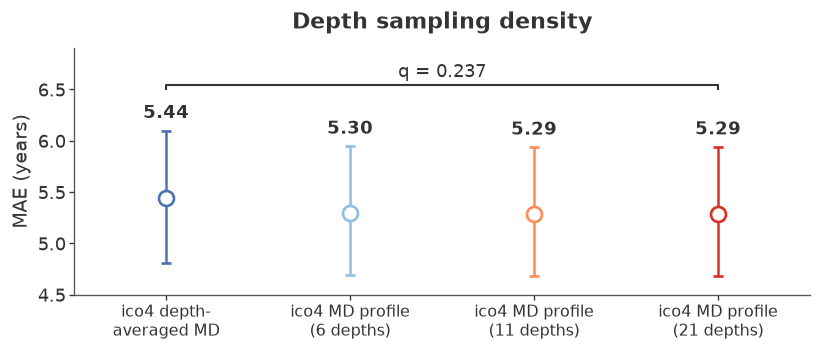

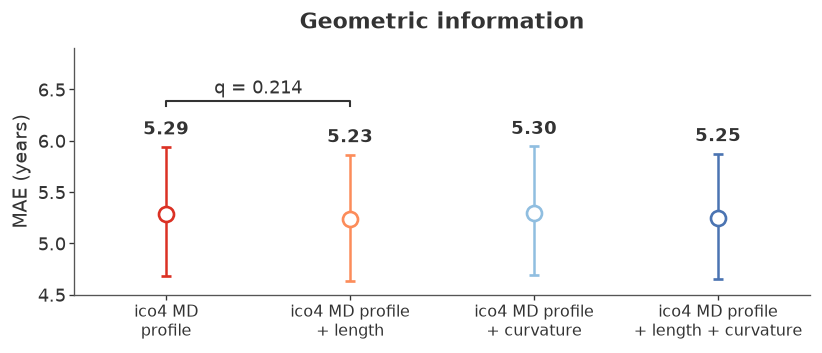

In [145]:
group_union = list(dict.fromkeys(SPATIAL_KEYS + DEPTH_KEYS + GEOMETRY_KEYS))
GROUP_YLIM, GROUP_YTICKS = mae_axis_limits(group_union)
GROUP_YLIM = (GROUP_YLIM[0], GROUP_YLIM[1] + 0.40)  # room for MAE labels and selected q-value brackets

def draw_q_bracket(ax, x1, x2, y, q_value, height=0.045):
    ax.plot([x1, x1, x2, x2], [y, y + height, y + height, y],
            color="#333333", linewidth=1.25, clip_on=False, zorder=6)
    ax.text((x1 + x2) / 2, y + height + 0.035, f"q = {q_value:.3f}",
            ha="center", va="bottom", fontsize=10.5, color="#333333", zorder=7)

def draw_vertical_group_panel(ax, keys, labels, colors, title, comparisons=None, ylim=None, yticks=None):
    rows = metric_ci.loc[metric_ci["metric"].eq("mae")].set_index("representation")
    x = np.arange(len(keys))
    ax.set_gid("group_mae_panel")
    for xpos, key in zip(x, keys):
        row = rows.loc[key]
        color = colors[key]
        artists = ax.errorbar(
            xpos, row["estimate"],
            yerr=[[row["estimate"] - row["ci95_lower"]], [row["ci95_upper"] - row["estimate"]]],
            fmt=POINT_MARKER, markersize=POINT_SIZE, markerfacecolor="white",
            markeredgecolor=color, markeredgewidth=POINT_EDGE_WIDTH, color=color,
            ecolor=color, elinewidth=ERROR_LINE_WIDTH, capsize=ERROR_CAP_SIZE,
            capthick=ERROR_CAP_THICKNESS, zorder=3,
        )
        data_line, cap_lines, bar_collections = artists.lines
        data_line.set_gid("metric_point")
        for artist in (*cap_lines, *bar_collections):
            artist.set_gid("metric_error")
        ax.annotate(
            f"{row['estimate']:.2f}", (xpos, row["ci95_upper"]), xytext=(0, 5),
            textcoords="offset points", ha="center", va="bottom", fontsize=10.5,
            fontweight="semibold", zorder=5,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.88, "pad": 0.8},
        )
    for key1, key2, q_value in comparisons or []:
        x1, x2 = keys.index(key1), keys.index(key2)
        pair_upper = rows.loc[[key1, key2], "ci95_upper"].max()
        draw_q_bracket(ax, x1, x2, pair_upper + 0.4, q_value)
    ax.set_xticks(x, labels, rotation=0, ha="center")
    ax.set_xlim(-0.5, len(keys) - 0.5)
    ylim = GROUP_YLIM if ylim is None else ylim
    yticks = GROUP_YTICKS if yticks is None else yticks
    ax.set_ylim(*ylim)
    ax.set_yticks(yticks)
    ax.set_title(title, fontsize=13, fontweight="bold", pad=12)
    ax.grid(False)
    ax.tick_params(axis="x", width=1.0, length=4, pad=7)
    ax.tick_params(axis="y", width=1.0, length=4)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

def make_vertical_group_figure(keys, labels, colors, title, stem, comparisons=None, ylim=None, yticks=None):
    fig, ax = plt.subplots(figsize=(7.09, 3.8))
    draw_vertical_group_panel(ax, keys, labels, colors, title, comparisons=comparisons, ylim=ylim, yticks=yticks)
    ax.set_ylabel("MAE (years)", fontsize=11.5)
    fig.subplots_adjust(left=0.12, right=0.985, bottom=0.30, top=0.84)
    save_figure(fig, stem)
    plt.show()
    return fig

fig_spatial = make_vertical_group_figure(
    SPATIAL_KEYS,
    ["Regional MD\nprofile", "ico3 MD\nprofile", "ico4 MD\nprofile",
     "ico5 MD\nprofile", "Full-resolution\nMD profile"],
    GROUP_COLORS["spatial"], "Spatial resolution",
    "Figure5B_spatial_resolution_MAE",
    comparisons=[("regional_profile", "ico4_md", rp_ico4["fdr_bh_q"])],
)
fig_depth = make_vertical_group_figure(
    DEPTH_KEYS,
    ["ico4 depth-\naveraged MD", "ico4 MD profile\n(6 depths)",
     "ico4 MD profile\n(11 depths)", "ico4 MD profile\n(21 depths)"],
    GROUP_COLORS["depth"], "Depth sampling density",
    "Figure5C_depth_sampling_MAE",
    comparisons=[("ico4_column_mean_md", "ico4_md", column_ico4["fdr_bh_q"])],
)
fig_geometry = make_vertical_group_figure(
    GEOMETRY_KEYS,
    ["ico4 MD\nprofile", "ico4 MD profile\n+ length",
     "ico4 MD profile\n+ curvature", "ico4 MD profile\n+ length + curvature"],
    GROUP_COLORS["geometry"], "Geometric information",
    "Figure5D_geometric_information_MAE",
    comparisons=[("ico4_md", "ico4_md_length", ico4_length["fdr_bh_q"])],
)

## 9. Supplementary regional representation comparison

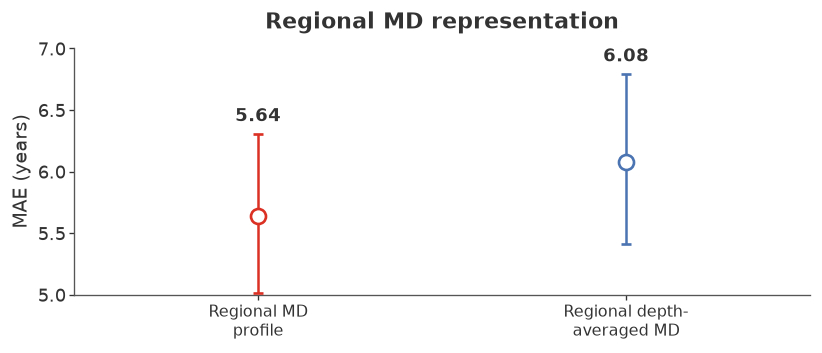

In [142]:
SUPPLEMENT_YLIM, SUPPLEMENT_YTICKS = mae_axis_limits(SUPPLEMENT_KEYS)
fig_supplement = make_vertical_group_figure(
    SUPPLEMENT_KEYS,
    ["Regional MD\nprofile", "Regional depth-\naveraged MD"],
    GROUP_COLORS["supplement"],
    "Regional MD representation",
    "FigureS5_regional_representation_MAE",
    ylim=SUPPLEMENT_YLIM, yticks=SUPPLEMENT_YTICKS,
)

## 10. Export complete metric tables and verify final files

In [143]:
all_metrics = qc_df[["representation", "model", "n", "mae", "rmse", "pearson_r", "r2"]].copy()
all_metrics["mae_rank"] = all_metrics["representation"].map({k: i + 1 for i, k in enumerate(EXPECTED_MAE_ORDER)})
all_metrics.sort_values("mae_rank").to_csv(OUTPUT_DIR / "Figure5_all_metrics.csv", index=False)

stems = ["Figure5A_MAE", "Figure5B_spatial_resolution_MAE",
         "Figure5C_depth_sampling_MAE", "Figure5D_geometric_information_MAE",
         "FigureS5_regional_representation_MAE"]
expected_files = [OUTPUT_DIR / f"{stem}.{suffix}" for stem in stems for suffix in ("png", "pdf", "svg")]
expected_files += [OUTPUT_DIR / "Figure5_all_metrics.csv", OUTPUT_DIR / "Figure5_all_metrics_bootstrap_ci.csv",
                   OUTPUT_DIR / "Figure5_plot_data.csv", OUTPUT_DIR / "Figure5_selected_paired_MAE_statistics.csv",
                   OUTPUT_DIR / "Figure5_exploratory_FDR_statistics.csv"]
missing_outputs = [str(p) for p in expected_files if not p.is_file()]
if missing_outputs:
    raise RuntimeError("Expected exports are missing:\n" + "\n".join(missing_outputs))

display(all_metrics.sort_values("mae_rank"))
display(selected_stats)
print("All Figure 5 and Supplementary Figure S5 outputs were written successfully.")

,representation,model,n,mae,rmse,pearson_r,r2,mae_rank
11,ico4_md_length,ico4 MD profile + length,196,5.233371,6.850516,0.769829,0.574227,1
13,ico4_md_length_curvature,ico4 MD profile + length + curvature,196,5.246867,6.850627,0.770821,0.574213,2
7,ico4_md_depth11,ico4 MD profile (11 depths),196,5.289505,6.930984,0.761464,0.564166,3
5,ico4_md,ico4 MD profile,196,5.290518,6.938888,0.761166,0.563171,4
12,ico4_md_curvature,ico4 MD profile + curvature,196,5.298498,6.935460,0.762435,0.563603,5
6,ico4_md_depth6,ico4 MD profile (6 depths),196,5.300022,6.919853,0.761787,0.565565,6
8,ico5_md,ico5 MD profile,196,5.363515,6.992468,0.757462,0.556399,7
9,fsaverage_full_md,Full-resolution MD profile,196,5.373040,6.970606,0.759687,0.559169,8
10,ico4_column_mean_md,ico4 depth-averaged MD,196,5.440511,7.099988,0.741245,0.542652,9
3,regional_profile_thickness,Regional MD profile + thickness,196,5.579632,7.160148,0.732607,0.534869,10


,family,family_label,representation_a,representation_b,comparison,comparison_order,n,delta_mae_a_minus_b,ci95_lower,ci95_upper,bootstrap_two_sided_p,bootstrap_replicates,bootstrap_seed,bootstrap_indices_shared_across_comparisons,delta_interpretation,fdr_bh_q,fdr_bh_significant_0_05,fdr_status
1,spatial_resolution,Exploratory spatial-resolution comparisons,regional_profile,ico4_md,Regional 21-depth profile − ico4,1,196,0.347735,0.057046,0.665469,0.021598,10000,20261028,True,positive values favor representation_b (lower ...,0.086391,False,included in exploratory/secondary comparison f...
2,spatial_resolution,Exploratory spatial-resolution comparisons,ico4_md,ico5_md,ico4 − ico5,2,196,-0.072997,-0.175077,0.027488,0.158584,10000,20261028,True,positive values favor representation_b (lower ...,0.317168,False,included in exploratory/secondary comparison f...
3,spatial_resolution,Exploratory spatial-resolution comparisons,ico5_md,fsaverage_full_md,ico5 − full fsaverage,3,196,-0.009525,-0.049617,0.029524,0.632137,10000,20261028,True,positive values favor representation_b (lower ...,0.775322,False,included in exploratory/secondary comparison f...
4,ico4_ablation,Exploratory ico4-ablation comparisons,ico4_column_mean_md,ico4_md,ico4 column mean MD − ico4,4,196,0.149993,-0.057946,0.364215,0.161984,10000,20261028,True,positive values favor representation_b (lower ...,0.237310,False,included in exploratory/secondary comparison f...
5,ico4_ablation,Exploratory ico4-ablation comparisons,ico4_md,ico4_md_length,ico4 − ico4 + length,5,196,0.057147,-0.000321,0.115386,0.053595,10000,20261028,True,positive values favor representation_b (lower ...,0.214379,False,included in exploratory/secondary comparison f...


All Figure 5 and Supplementary Figure S5 outputs were written successfully.


## 11. Statistical provenance and caption drafts

In [144]:
caption = f"""**Figure 5. Brain-age prediction performance.**
**A, Overview across cortical representations.** Mean absolute error (MAE), ordered from lower to higher MAE; models dedicated to depth-sampling comparisons are omitted because they are shown in panel C or Supplementary Figure S5. All overview models are shown in dark blue because color does not encode model identity. **B–D, Grouped comparisons.** The three comparisons are exported as separate figures with the same MAE axis range and ticks; full model names are placed on the horizontal axis and no connecting lines are drawn. **B, Spatial resolution.** Regional, ico3, ico4, ico5, and full-resolution MD profiles are shown in experimental order. **C, Depth sampling density.** ico4 depth-averaged MD and ico4 MD profiles sampled at 6, 11, and 21 depth points are shown in experimental order. **D, Geometric information.** The ico4 MD profile is compared with models augmented by length, curvature, or both. Red identifies the core ico4 21-depth representation in each grouped comparison. Unless a depth count is stated explicitly, an MD profile contains 21 cortical-depth samples. Points show MAE calculated by pooling held-out predictions from the outer folds of nested cross-validation for all {n_subjects} participants (OOF predictions). Error bars show percentile subject-bootstrap 95% confidence intervals from {BOOTSTRAP_REPLICATES:,} shared resamples (seed {BOOTSTRAP_SEED}). Selected brackets show FDR-adjusted q values for the prespecified comparisons; full paired statistics are retained in the accompanying table. No all-model pairwise testing, ΔMAE panel, radar plot, or dense significance brackets are displayed."""

supp_caption = f"""**Supplementary Figure S5. Regional MD representation.**
Regional MD profile (21 cortical-depth samples) is compared with regional depth-averaged MD. Points show MAE from the pooled outer-fold held-out predictions of nested cross-validation for all {n_subjects} participants; error bars show percentile subject-bootstrap 95% confidence intervals from {BOOTSTRAP_REPLICATES:,} shared resamples (seed {BOOTSTRAP_SEED})."""

display(Markdown(caption))
display(Markdown(supp_caption))
print(f"Exploratory/secondary FDR statistics: {PAIRED_MAE_STATS}")
print("Paired comparisons remain available in the statistics table and are not drawn as dense brackets.")

**Figure 5. Brain-age prediction performance.**
**A, Overview across cortical representations.** Mean absolute error (MAE), ordered from lower to higher MAE; models dedicated to depth-sampling comparisons are omitted because they are shown in panel C or Supplementary Figure S5. All overview models are shown in dark blue because color does not encode model identity. **B–D, Grouped comparisons.** The three comparisons are exported as separate figures with the same MAE axis range and ticks; full model names are placed on the horizontal axis and no connecting lines are drawn. **B, Spatial resolution.** Regional, ico3, ico4, ico5, and full-resolution MD profiles are shown in experimental order. **C, Depth sampling density.** ico4 depth-averaged MD and ico4 MD profiles sampled at 6, 11, and 21 depth points are shown in experimental order. **D, Geometric information.** The ico4 MD profile is compared with models augmented by length, curvature, or both. Red identifies the core ico4 21-depth representation in each grouped comparison. Unless a depth count is stated explicitly, an MD profile contains 21 cortical-depth samples. Points show MAE calculated by pooling held-out predictions from the outer folds of nested cross-validation for all 196 participants (OOF predictions). Error bars show percentile subject-bootstrap 95% confidence intervals from 10,000 shared resamples (seed 20261028). Selected brackets show FDR-adjusted q values for the prespecified comparisons; full paired statistics are retained in the accompanying table. No all-model pairwise testing, ΔMAE panel, radar plot, or dense significance brackets are displayed.

**Supplementary Figure S5. Regional MD representation.**
Regional MD profile (21 cortical-depth samples) is compared with regional depth-averaged MD. Points show MAE from the pooled outer-fold held-out predictions of nested cross-validation for all 196 participants; error bars show percentile subject-bootstrap 95% confidence intervals from 10,000 shared resamples (seed 20261028).

Exploratory/secondary FDR statistics: /mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis/analysis_results/figure5/outputs/statistics/Figure5_paired_MAE_comparisons.csv
Paired comparisons remain available in the statistics table and are not drawn as dense brackets.
